In [84]:
import numpy as np
import matplotlib.pyplot as plt

In [85]:
deg         = np.pi / 180
Ah          = 1.745276391348672e-20
As          = 1.5e10 # tem cara do alpha ser multiplicado por isso
hs          = 0.05e-9
sigma       = 25e-3 # Phreqc
Tc          = 338.0 - 273.15
e           = 1.602217663e-19
eps0        = 8.854e-12
epsr        = 71.715238
kB          = 1.380649e-23
NA          = 6.02214076e23
I           = 0.05#4# Phreqc

Inverso da distância de Debeye

$$\kappa  = \sqrt {\frac{{e_c^2{N_A}I}}{{{\varepsilon _0}{\varepsilon _r}{k_B}T}}} $$

quando $I$ é dado em mol/L é necessário multiplicá-lo por 1000 a fim de transformá-lo em mol/m³.

In [86]:
def calcula_kappa(e, NA, I, epsr, eps0, kB, Tc):
    num = (e**2) * NA * I * 1e3
    den = epsr * eps0 * kB * (Tc + 273.15)
    return np.sqrt(num/den)

$$\varepsilon_0\varepsilon_3\kappa^2\left[\frac{2\,\psi_1\psi_2\cosh{\left(\kappa h_0\right)}-\left(\psi_1^2+\psi_2^2\right)}{2\,{\sinh}^2{\left(\kappa h_0\right)}}\right]-\frac{A_h}{6\pi h_0^3}+A_se^{-\frac{h_0}{h_s}}=0$$

In [87]:
def f(x0, V1, V2, eps0, epsr, Ah, As, kappa, hs):
    t1 = eps0 * epsr * (kappa ** 2.0)
    t2 = 2 * V1 * V2 * np.cosh(kappa * x0)
    t3 = (V1 ** 2) + (V2 ** 2)
    num = t1 * (t2 - t3)
    den = 2 * (np.sinh(kappa * x0)) ** 2
    Pedl = num / den
    Ps = As * np.exp(-x0 / hs)
    Pvdw = Ah / (6 * np.pi * (x0 ** 3))
    soma = Pedl + Ps - Pvdw
    return soma

In [88]:
def estrutural(x, V1, V2, eps0, epsr, Ah, As, kappa, hs):
    Ps = As * np.exp(-x / hs)
    return Ps


In [89]:
def dupla_camada(x, V1, V2, eps0, epsr, Ah, As, kappa, hs):
    t1 = eps0 * epsr * (kappa ** 2.0) #nb*kb*T
    t2 = 2 * V1 * V2 * np.cosh(kappa * x)
    t3 = (V1 ** 2) + (V2 ** 2)
    num = t1 * (t2 - t3)
    den = 2 * (np.sinh(kappa * x)) ** 2
    Pedl = num / den
    return Pedl

In [90]:
def van_der_Walls(x, V1, V2, eps0, epsr, Ah, As, kappa, hs):
    Pvdw = - Ah / (6 * np.pi * (x ** 3))
    return Pvdw

In [91]:
def newton_raphson(kappa, x0, V1, V2, eps0, epsr, Ah, As, hs, N=10000, erro=1):
    cont = 0
    dx = 1e-16

    while True:
        f0 = f(x0, V1, V2, eps0, epsr, Ah, As, kappa, hs)
        g0 = (f(x0+dx, V1, V2, eps0, epsr, Ah, As, kappa, hs) - f(x0-dx, V1, V2, eps0, epsr, Ah, As, kappa, hs)) / (2*dx)

        if g0 == 0:
            g0 = 1e-3

        x1 = x0 - f0 / g0
        x0 = x1
        f1 = f(x1, V1, V2, eps0, epsr, Ah, As, kappa, hs)

        cont = cont + 1

        if cont > N:
            continua = False
            break

        if abs(f1) <= erro:
            continua = True
            break

    return [x1, continua]

$$\varepsilon_0\varepsilon_3\kappa^2\left[\frac{2\,\psi_1\psi_2\cosh{\left(\kappa h_0\right)}-\left(\psi_1^2+\psi_2^2\right)}{2\,{\sinh}^2{\left(\kappa h_0\right)}}\right]-\frac{A_h}{6\pi h_0^3}+A_se^{-\frac{h_0}{h_s}}=0$$

In [92]:
def espessura_de_equilibrio(kappa, V1, V2, eps0, epsr, Ah, As, hs, xhmin=0.01e-9):
    x1, continua = newton_raphson(kappa=kappa, x0=xhmin, V1=V1, V2=V2, eps0=eps0, epsr=epsr, Ah=Ah, As=As, hs=hs)
    if continua==True:
        root = x1
        saida = x1
    else:
        saida = 'Not Convergent.'
    return saida

In [93]:
kappa = calcula_kappa(e, NA, I, epsr, eps0, kB, Tc)
1/kappa

1.957913513207709e-09

In [94]:
V1 = -0.035700
V2 = -0.044607
ee = espessura_de_equilibrio(kappa=kappa, V1=V1, V2=V2, eps0=eps0, epsr=epsr, Ah=Ah, As=As, xhmin=0.01e-9, hs=hs)
ee*1e12


58.3387964761509

In [95]:
x = 1e-9
t1 = eps0 * epsr * (kappa ** 2.0) #nb*kb*T
t2 = 2 * V1 * V2 * np.cosh(kappa * x)
t3 = (V1 ** 2) + (V2 ** 2)
num = t1 * (t2 - t3)
den = 2 * (np.sinh(kappa * x)) ** 2
Pedl = num / den
Pedl

100540.405507832

Text(0.5, 1.0, 'Pressão DLVO')

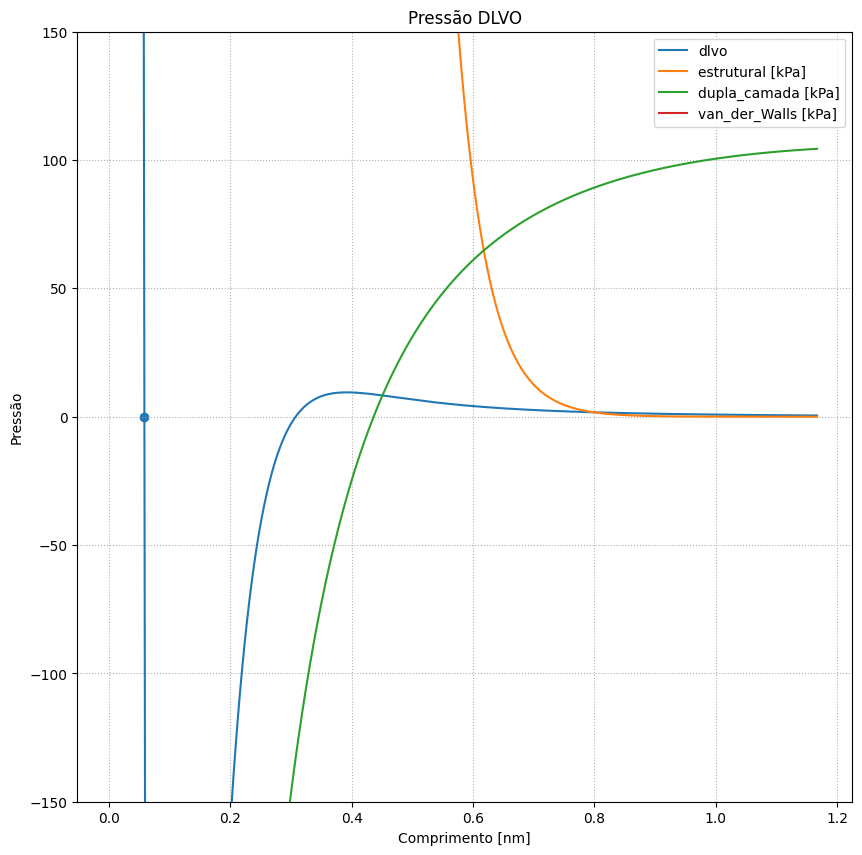

In [96]:
hh = np.geomspace(0.1*ee, 20*ee, 1000000)
fig, ax = plt.subplots(figsize=(10,10), dpi=100)
x = hh
y = f(x, V1, V2, eps0, epsr, Ah, As, kappa, hs)
ax.plot(x/1e-9, y/1e6, label='dlvo')

x = hh
y = estrutural(x, V1, V2, eps0, epsr, Ah, As, kappa, hs)
ax.plot(x/1e-9, y/1e3, label='estrutural [kPa]')

x = hh
y = dupla_camada(x, V1, V2, eps0, epsr, Ah, As, kappa, hs)
ax.plot(x/1e-9, y/1e3, label='dupla_camada [kPa]')

x = hh
y = van_der_Walls(x, V1, V2, eps0, epsr, Ah, As, kappa, hs)
ax.plot(x/1e-9, y/1e3, label='van_der_Walls [kPa]')

x = ee
y = f(x, V1, V2, eps0, epsr, Ah, As, kappa, hs)
ax.scatter(x/1e-9, y/1e3)

ax.legend()
ax.set_ylim(-150, 150)
ax.set_xlabel('Comprimento [nm]')
ax.set_ylabel('Pressão')
ax.grid(ls=":")
ax.set_title('Pressão DLVO')
